# Best Model ( Random Forest ) After PCA

## Objectives
Apply PCA to the best Random Forest model while retaining
95% of the explained variance.

Compare the original Random Forest with Random Forest + PCA
using the same training and testing data.


Import libraries

In [ ]:
# Work with data
import pandas as pd

# Load the saved Random Forest model
import joblib

# Standardize features and apply PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Build the Random Forest with the same hyperparameters
from sklearn.ensemble import RandomForestClassifier

# Evaluate model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
def metrics(y, pred):
    return {
        'accuracy': accuracy_score(y, pred),
        'macro_precision': precision_score(y, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y, pred, average='macro', zero_division=0)
        }

Load the files

Evaluate the saved best Random Forest
 model using the test data.
These results will be compared with Random Forest after applying PCA.

In [ ]:
# Load training and testing features
X_train = pd.read_csv("/content/X_train.csv")
X_test = pd.read_csv("/content/X_test.csv")


# Load training and testing labels as one-dimensional arrays
# .squeeze("columns") method converts a one-column DataFrame into a Series,
#which is the expected format for classification labels.
y_train = pd.read_csv("/content/y_train.csv").squeeze("columns")
y_test = pd.read_csv("/content/y_test.csv").squeeze("columns")


# Load Lama trained best model
#best_model = joblib.load("/content/best_model.joblib")
before_pca = pd.read_csv("/content/best_model.csv")

# Display the saved model
print("The best model results before pca: ")
print(before_pca)

print()

# Display the number of rows and columns
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print()

# # Display the type of the saved model
# print("Model type:", type(best_model))

The best model results before pca: 
           model  accuracy  macro_precision  macro_recall  macro_f1
0  Random Forest  0.995455         0.995671      0.995455  0.995452

X_train: (1760, 7)
X_test: (440, 7)
y_train: (1760,)
y_test: (440,)



**Apply PCA**

Standardize the features

In [ ]:
# Create the scaler
scaler = StandardScaler()

# Standardize the training features
X_train_scaled = scaler.fit_transform(X_train)

# Standardize the testing features using the same scaler
X_test_scaled = scaler.transform(X_test)



use PCA() function from scikit-learn

In [69]:
# Create PCA to retain at least 95% of the variance
pca = PCA(n_components=0.95)

# Apply PCA to the standardized training features
X_train_pca = pca.fit_transform(X_train_scaled)

# Apply the same PCA transformation to the standardized testing features
X_test_pca = pca.transform(X_test_scaled)

In [70]:
# Display the original number of features
print("Original features:", X_train.shape[1])

# Display the number of components selected by PCA
print("PCA components:", pca.n_components_)

# Display the total explained variance retained by PCA
print("Explained variance:", round(sum(pca.explained_variance_ratio_), 4))

Original features: 7
PCA components: 6
Explained variance: 0.9724


Train Random Forest after PCA

In [71]:
# Copy the best Random Forest model with the same hyperparameters
#clone(best_model) creates a new Random Forest with the same settings as the original model
#(n_estimators=200, random_state=42, n_jobs=-1)
best_model_pca = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
3
# Train Random Forest using the PCA-transformed training data
best_model_pca.fit(X_train_pca, y_train)

# Predict crops using the PCA-transformed testing data
y_pred_pca = best_model_pca.predict(X_test_pca)

#metrics
scores_after_pca = metrics(y_test, y_pred_pca)


# Create a DataFrame with the same structure as best_model.csv
after_pca = pd.DataFrame([{
    "model": "Random Forest after PCA",
    **scores_after_pca
}])

# Save to CSV
after_pca.to_csv("best_model_pca.csv", index=False)

# Display the results
print(after_pca.round(4).to_string(index=False))

                  model  accuracy  macro_precision  macro_recall  macro_f1
Random Forest after PCA    0.9773           0.9785        0.9773    0.9771


Evaluate Random Forest after PCA

In [72]:
 comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Random Forest before PCA": [
        before_pca.loc[0, "accuracy"],
        before_pca.loc[0, "macro_precision"],
        before_pca.loc[0, "macro_recall"],
        before_pca.loc[0, "macro_f1"]
    ],
    "Random Forest after PCA": [
        after_pca.loc[0, "accuracy"],
        after_pca.loc[0, "macro_precision"],
        after_pca.loc[0, "macro_recall"],
        after_pca.loc[0, "macro_f1"]
    ]
})

# Display the comparison table
print(comparison_df.round(4))

            Metric  Random Forest before PCA  Random Forest after PCA
0         Accuracy                    0.9955                   0.9773
1  Macro Precision                    0.9957                   0.9785
2     Macro Recall                    0.9955                   0.9773
3         Macro F1                    0.9955                   0.9771


In [73]:
# Save the comparison results as a CSV file
comparison_df.to_csv("random_forest_pca_comparison.csv", index=True)

# Confirm the file was saved
print("CSV file saved successfully!")

CSV file saved successfully!


Create the comparison table

**Interpretation of Results**

PCA reduced the number of features from 7 to 6 principal components while retaining at least 95% of the explained variance.

However, this dimensionality reduction resulted in slightly lower classification performance.

Conclusion: PCA did not improve the Random Forest model's performance in this experiment. Therefore, the original Random Forest is preferred because it achieved higher scores across all evaluation metrics.

Visualize the comparison

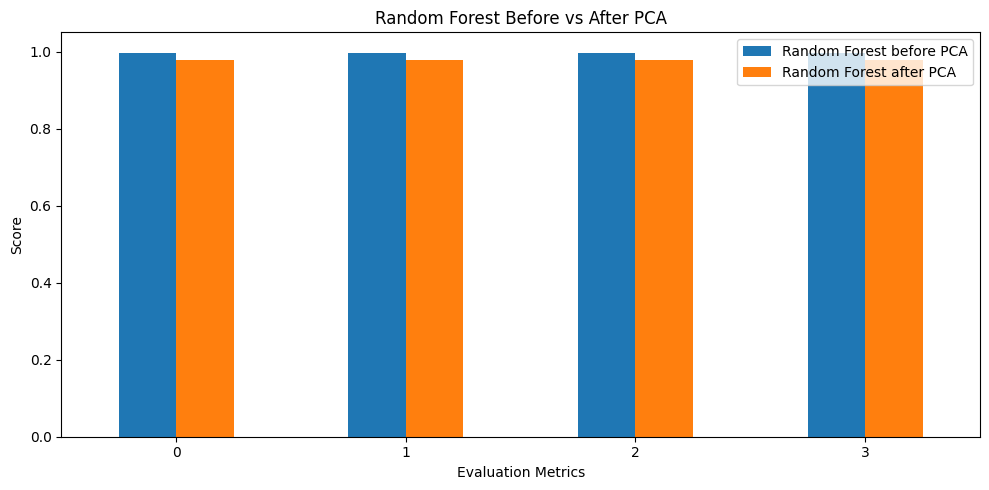

In [75]:
import matplotlib.pyplot as plt

# Create a bar chart to compare both models
comparison_df.plot(kind="bar", figsize=(10, 5))

# Add a title to the chart
plt.title("Random Forest Before vs After PCA")

# Label the x-axis
plt.xlabel("Evaluation Metrics")

# Label the y-axis
plt.ylabel("Score")

# Set the y-axis range to highlight differences
# Display the full score from 0% to 100%
plt.ylim(0, 1.05)

# Display metric names horizontally
plt.xticks(rotation=0)

# Adjust spacing
plt.tight_layout()

#save figure
plt.savefig("Fig4_best model after PCA bars.png", dpi=300)

# Display the chart
plt.show()

## Summary and Conclusion

In this experiment, PCA was applied to the best Random Forest model to investigate whether dimensionality reduction could improve its performance.

PCA reduced the original 7 features to 6 principal components while retaining at least 95% of the explained variance. However, accuracy decreased from **99.55% to 97.73%**, and the other evaluation metrics also decreased slightly.

PCA did not improve performance because it preserves directions with high variance rather than necessarily preserving the information most useful for predicting crop types. Additionally, Random Forest can effectively handle the original features without requiring dimensionality reduction.

Since our dataset contains only 7 features, PCA provided limited dimensionality reduction and did not offer a performance advantage.

**In conclusion, PCA does not always improve machine learning performance.** Its usefulness depends on the dataset and the model. For our crop recommendation system, the original Random Forest achieved better results and is therefore the preferred model.